In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix

In [ ]:
df = pd.read_csv("03_phishing_email.csv")

X = df["text_combined"]
y = df["label"]

In [ ]:
df.head(5)

,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
tfidf = TfidfVectorizer()

X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

In [ ]:
model = LinearSVC()

model.fit(X_train, y_train)

LinearSVC()

In [ ]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\ncm:",confusion_matrix(y_test,y_pred))
print("\nreport:",classification_report(y_test, y_pred))

Accuracy: 0.9909079888471329

cm: [[7837   82]
 [  68 8511]]

report:               precision    recall  f1-score   support

           0       0.99      0.99      0.99      7919
           1       0.99      0.99      0.99      8579

    accuracy                           0.99     16498
   macro avg       0.99      0.99      0.99     16498
weighted avg       0.99      0.99      0.99     16498



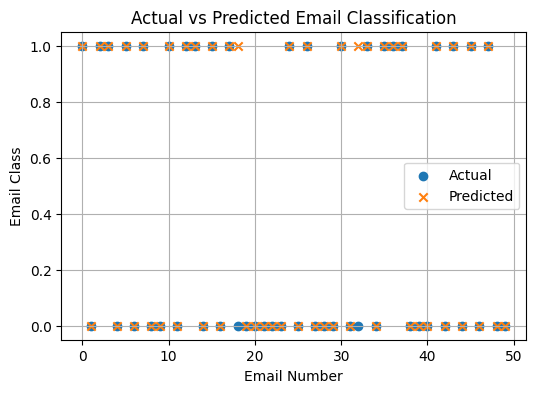

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.scatter(range(50), y_test[:50], label="Actual", marker="o")
plt.scatter(range(50), y_pred[:50], label="Predicted", marker="x")

plt.xlabel("Email Number")
plt.ylabel("Email Class")
plt.title("Actual vs Predicted Email Classification")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Test a new email
new_mail = ["Congratulations! You won a prize. Click here to claim your reward"]

# Convert email into TF-IDF features
new_mail_tfidf = tfidf.transform(new_mail)

# Predict email class
prediction = model.predict(new_mail_tfidf)

if prediction[0] == 1:
    print("Email is Phishing")
else:
    print("Email is Legitimate")

Email is Phishing


# OR

                                       text_combined  label
0  hpl nom may 25 2001 see attached file hplno 52...      0
1  nom actual vols 24 th forwarded sabrae zajac h...      0
2  enron actuals march 30 april 1 201 estimated a...      0
3  hpl nom may 30 2001 see attached file hplno 53...      0
4  hpl nom june 1 2001 see attached file hplno 60...      0
Index(['text_combined', 'label'], dtype='object')
Accuracy: 97.86640804946055 %
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      7935
           1       0.99      0.97      0.98      8563

    accuracy                           0.98     16498
   macro avg       0.98      0.98      0.98     16498
weighted avg       0.98      0.98      0.98     16498



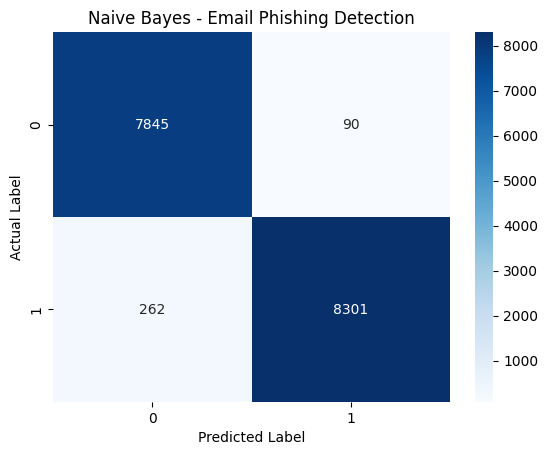

Email Classification: 0


In [ ]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 2. Load dataset
df = pd.read_csv("03_phishing_email.csv")
print(df.head())
print(df.columns)

# 3. Remove missing values
df = df.dropna()

# 4. Select email text and label columns
X = df['text_combined']
y = df['label']

# 5. Convert email text into numerical features
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(X)

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Train Naive Bayes model
model = MultinomialNB()
model.fit(X_train, y_train)

# 8. Predict results
y_pred = model.predict(X_test)

# 9. Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

# 10. Classification report
print(classification_report(y_test, y_pred))

# 11. Plot confusion matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Naive Bayes - Email Phishing Detection")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# 12. Test a new email
email = ["Hi John, the team meeting is scheduled for tomorrow at 10 AM. Please review the project report before the meeting."]

email_vector = vectorizer.transform(email)

print("Email Classification:", model.predict(email_vector)[0])